# Pulls vs magnitude: are the per-epoch errors right?

Error model: sigma_total^2 = (k sigma_stat)^2 + sigma_sys^2, adopted k = 1, sigma_sys per band from this notebook (g 16, r 12, i 12, z 10 mas) (`py_files/error_model.py`).
If it is right, the pulls (residual from each star's straight-line PM fit / sigma_total, scaled by sqrt(N / (N - 2)) for
the two fitted parameters per axis) have unit width at **every** magnitude: sigma_sys sets the bright end, sigma_stat the faint end.
A width that rises for faint stars means sigma_stat is underestimated (k > 1); one that is off only for bright stars means
sigma_sys is wrong.

Data: per-epoch residuals from `py_files/pm_pulls.py` (compute node; random 25% of the bricks of one slice), clean
objects (pm_quality == 0 apart from BAD_EPOCHS), all PSF objects (not only Gaia), magnitude in the epoch's band.
Width = robust (1.4826 x MAD), so it tracks the core; the tail fraction |pull| > 5 is shown separately (BAD_EPOCHS).
**Found 2026-10-23:** inputs written before legacypipe commit 7aece157 (2026-09-16) have `full_fit_ddec_ivar` too
large by 1/cos^2(Dec) (sigma_Dec / sigma_RA = cos Dec; faint-star Dec pulls ~1/cos Dec). `pm_pulls.py` now applies the
pipeline's per-brick correction (`error_model.corrected_ddec_ivar`), so sigma_dec here is already corrected.
Caveat (2026-10-23): slice 000 was processed before the two-line DCR model; rerun after the pipeline rerun.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath('..'))
from py_files import plot_style as ps
from py_files.error_model import sigma_sys
ps.apply()
SLICE, FRACTION = '000', 0.25
D = dict(np.load(f'/pscratch/sd/n/nelfalou/legacypm-catalogue-v2/combined/pulls-{SLICE}-{FRACTION}.npz'))
BANDS = 'griz'
print(f"Dec-ivar bug corrected for {D['decfix'].mean():.0%} of epochs")
sel = D['clean'] & np.isfinite(D['mag']) & (D['n'] >= 10)
D = {k: v[sel] for k, v in D.items()}
dof = np.sqrt(D['n'] / (D['n'] - 2.))
rs = lambda v: 1.4826 * np.median(np.abs(v - np.median(v)))
mb = np.arange(15, 26.01, 0.5); mc = 0.5 * (mb[1:] + mb[:-1])
ibin = np.digitize(D['mag'], mb) - 1
print(f"{len(D['mag']):,} epochs of {len(np.unique(D['obj'])):,} clean objects")
# faint-star (sigma_stat-dominated) pull width per Dec band: should be ~1 everywhere in both axes
faint = D['mag'] > 23
for lo in range(-90, 40, 15):
    m = faint & (D['dec'] >= lo) & (D['dec'] < lo + 15)
    if m.sum() > 1000:
        print(f"Dec {lo:+d}..{lo + 15:+d}: faint stat-only pull width RA {rs((D['res_ra'] / D['sig_ra'] * dof)[m]):.2f}  "
              f"Dec {rs((D['res_dec'] / D['sig_dec'] * dof)[m]):.2f}  ({m.sum():,} epochs)")

SYS_EPOCH = sigma_sys(np.array(list(BANDS))[D['band']])   # adopted sigma_sys of each epoch's band

def pulls(ax, k=1., sys=SYS_EPOCH):
    return D[f'res_{ax}'] / np.sqrt((k * D[f'sig_{ax}'])**2 + sys**2) * dof

def width_by_mag(p, m, stat=rs):
    return np.array([stat(p[m & (ibin == j)]) if (m & (ibin == j)).sum() >= 300 else np.nan for j in range(len(mc))])

Dec-ivar bug corrected for 100% of epochs


24,444,790 epochs of 777,327 clean objects
Dec -90..-75: faint stat-only pull width RA 0.96  Dec 0.98  (668,756 epochs)


Dec -75..-60: faint stat-only pull width RA 0.90  Dec 0.91  (4,961,006 epochs)


Dec -60..-45: faint stat-only pull width RA 0.95  Dec 0.96  (4,682,528 epochs)


Dec -45..-30: faint stat-only pull width RA 0.94  Dec 0.95  (4,178,068 epochs)
Dec -30..-15: faint stat-only pull width RA 0.98  Dec 0.98  (744,003 epochs)


Dec -15..+0: faint stat-only pull width RA 0.98  Dec 0.99  (3,166,298 epochs)


Dec +0..+15: faint stat-only pull width RA 0.97  Dec 0.98  (2,165,347 epochs)
Dec +15..+30: faint stat-only pull width RA 1.01  Dec 1.02  (677,399 epochs)


## Pull width vs magnitude for the current model (k = 1, sigma_sys = 20) and statistical errors only

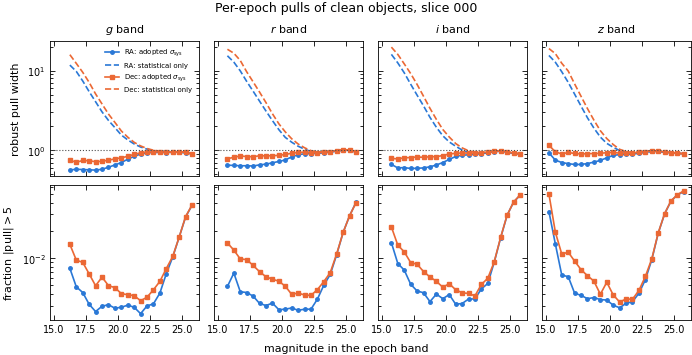

In [2]:
fig, axes = plt.subplots(2, 4, figsize=(ps.PAGE, 3.6), sharex=True, sharey='row', constrained_layout=True)
for j, b in enumerate(BANDS):
    m = D['band'] == j
    for k_, (ax, lab) in enumerate((('ra', 'RA'), ('dec', 'Dec'))):
        axes[0, j].plot(mc, width_by_mag(pulls(ax), m), marker=ps.MARKERS[k_], ms=2.5, color=ps.SERIES[k_],
                        label=f'{lab}: adopted $\\sigma_{{\\rm sys}}$')
        axes[0, j].plot(mc, width_by_mag(pulls(ax, sys=0.), m), ls='--', color=ps.SERIES[k_], label=f'{lab}: statistical only')
        axes[1, j].plot(mc, width_by_mag(pulls(ax), m, lambda v: np.mean(np.abs(v) > 5)), marker=ps.MARKERS[k_], ms=2.5,
                        color=ps.SERIES[k_], label=lab)
    axes[0, j].axhline(1, color='0.3', ls=':', lw=0.8)
    axes[0, j].set_title(f'${b}$ band'); axes[0, j].set_yscale('log')
    axes[1, j].set_yscale('log')
axes[0, 0].set_ylabel('robust pull width'); axes[1, 0].set_ylabel(r'fraction $|$pull$| > 5$')
axes[0, 0].legend(fontsize=5); fig.supxlabel('magnitude in the epoch band', fontsize=8)
fig.suptitle(f'Per-epoch pulls of clean objects, slice {SLICE}')
plt.savefig('plots/pull_width_vs_mag.pdf')

## Fit k and sigma_sys per band

Choose (k, sigma_sys) so the robust pull width is 1 in every magnitude bin (least squares of log width over bins,
RA and Dec together), on a grid.

In [3]:
KS = np.arange(0.8, 3.01, 0.1); SYS = np.arange(0., 40.1, 2.)
best = {}
for j, b in enumerate(BANDS):
    m = D['band'] == j
    # subsample for speed
    idx = np.flatnonzero(m); idx = idx[np.random.default_rng(0).permutation(len(idx))[:300_000]]
    cost = np.zeros((len(KS), len(SYS)))
    for a, k in enumerate(KS):
        for c, s in enumerate(SYS):
            w = []
            for ax in ('ra', 'dec'):
                p = D[f'res_{ax}'][idx] / np.sqrt((k * D[f'sig_{ax}'][idx])**2 + s**2) * dof[idx]
                ib = ibin[idx]
                w += [rs(p[ib == q]) for q in range(len(mc)) if (ib == q).sum() >= 300]
            cost[a, c] = np.sum(np.log(np.array(w))**2)
    a, c = np.unravel_index(np.argmin(cost), cost.shape)
    best[b] = (KS[a], SYS[c])
    print(f'{b}: k = {KS[a]:.2f}, sigma_sys = {SYS[c]:.0f} mas   (k fixed at 1: best sigma_sys = {SYS[np.argmin(cost[np.argmin(np.abs(KS - 1))])]:.0f} mas)')

g: k = 1.00, sigma_sys = 10 mas   (k fixed at 1: best sigma_sys = 10 mas)


r: k = 1.00, sigma_sys = 8 mas   (k fixed at 1: best sigma_sys = 8 mas)


i: k = 1.00, sigma_sys = 8 mas   (k fixed at 1: best sigma_sys = 8 mas)


z: k = 0.90, sigma_sys = 8 mas   (k fixed at 1: best sigma_sys = 8 mas)


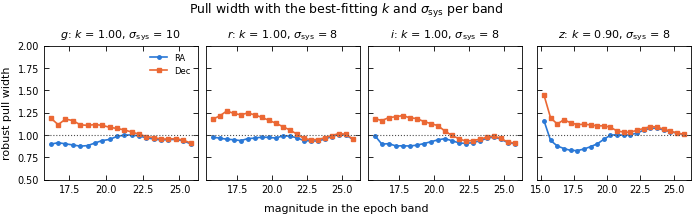

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(ps.PAGE, 2.2), sharey=True, constrained_layout=True)
for j, b in enumerate(BANDS):
    m = D['band'] == j
    k, s = best[b]
    for k_, (ax, lab) in enumerate((('ra', 'RA'), ('dec', 'Dec'))):
        axes[j].plot(mc, width_by_mag(pulls(ax, k, s), m), marker=ps.MARKERS[k_], ms=2.5, color=ps.SERIES[k_], label=lab)
    axes[j].axhline(1, color='0.3', ls=':', lw=0.8)
    axes[j].set_title(f'${b}$: $k$ = {k:.2f}, $\\sigma_{{\\rm sys}}$ = {s:.0f}')
axes[0].set_ylabel('robust pull width'); axes[0].legend(fontsize=6); axes[0].set_ylim(0.5, 2)
fig.supxlabel('magnitude in the epoch band', fontsize=8)
fig.suptitle('Pull width with the best-fitting $k$ and $\\sigma_{\\rm sys}$ per band')
plt.savefig('plots/pull_width_bestfit.pdf')